In [6]:
import sys
sys.path.insert(0, "/Users/bohaoli/Desktop/tuto/tuto_langchain/official/langchain-langgraph-langsmith/utils")

from utils import ppm, ppms, debug

<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🎯 带 Profile Schema 的 Chatbot

**一句话定位**:让记忆不再是一段裸字符串,而是一个有结构、可持续更新的 user profile。

</div>

## 回顾

上一节引入了 [LangGraph Memory Store](https://reference.langchain.com/python/langgraph/store/?h=basestor#langgraph.store.base.BaseStore),搭了个同时有 `short-term` 和 `long-term` 记忆的 chatbot,长期的 [semantic memory](https://docs.langchain.com/oss/python/concepts/memory#semantic-memory)(用户事实)在对话中["in the hot path"](https://docs.langchain.com/oss/python/concepts/memory#writing-memories)实时保存。

## 目标

之前记忆是存成一段字符串的。实战中我们常常希望记忆**有结构**,比如 [单一、持续更新的 schema](https://docs.langchain.com/oss/python/concepts/memory#profile)——这里就是一份用户画像(user profile)。

要把 chatbot 升级成把语义记忆存成单一 [user profile](https://docs.langchain.com/oss/python/concepts/memory#profile),并引入 [Trustcall](https://github.com/hinthornw/trustcall) 库来用新信息更新这份 schema。

In [1]:
import os, getpass

def _set_env(var: str):
    # Check if the variable is set in the OS environment
    env_value = os.environ.get(var)
    if not env_value:
        # If not set, prompt the user for input
        env_value = getpass.getpass(f"{var}: ")
    
    # Set the environment variable for the current process
    os.environ[var] = env_value

_set_env("LANGSMITH_API_KEY")
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_PROJECT"] = "langchain-academy"

## 定义 user profile schema

Python 里有很多[结构化数据](https://docs.langchain.com/oss/python/langchain/models#structured-outputs)的写法,比如 TypedDict、Dictionary、JSON、[Pydantic](https://docs.pydantic.dev/latest/)。先用 TypedDict 定义一个 user profile schema。

In [2]:
from typing import TypedDict, List


class UserProfile(TypedDict):
    """User profile schema with typed fields"""

    user_name: str  # The user's preferred name
    interests: List[str]  # A list of the user's interests

## 把 schema 存进 store

[LangGraph Store](https://reference.langchain.com/python/langgraph/store/?h=basestor#langgraph.store.base.BaseStore) 的 `value` 可以接受任意 Python 字典。

In [3]:
# TypedDict instance
user_profile: UserProfile = {
    "user_name": "Lance",
    "interests": ["biking", "technology", "coffee"],
}
user_profile

{'user_name': 'Lance', 'interests': ['biking', 'technology', 'coffee']}

用 [put](https://reference.langchain.com/python/langgraph/store/?h=basestor#langgraph.store.base.BaseStore.put) 方法把 TypedDict 存进 store。

In [4]:
import uuid
from langgraph.store.memory import InMemoryStore

# Initialize the in-memory store
in_memory_store = InMemoryStore()

# Namespace for the memory to save
user_id = "1"
namespace_for_memory = (user_id, "memory")

# Save a memory to namespace as key and value
key = "user_profile"
value = user_profile
in_memory_store.put(namespace_for_memory, key, value)

用 [search](https://reference.langchain.com/python/langgraph/store/?h=basestor#langgraph.store.base.BaseStore.search) 按 namespace 检索对象。

In [7]:
# Search
for m in in_memory_store.search(namespace_for_memory):
    debug(m.dict())

╭─────────────────────────────────────────────────── 🧠 Debug ────────────────────────────────────────────────────╮
│ {                                                                                                               │
│   "namespace": [                                                                                                │
│     "1",                                                                                                        │
│     "memory"                                                                                                    │
│   ],                                                                                                            │
│   "key": "user_profile",                                                                                        │
│   "value": {                                                                                                    │
│     "user_name": "Lance",                                                                                       │
│     "interests": [                                                                                              │
│       "biking",                                                                                                 │
│       "technology",                                                                                             │
│       "coffee"                                                                                                  │
│     ]                                                                                                           │
│   },                                                                                                            │
│   "created_at": "2026-05-07T03:39:04.724063+00:00",                                                             │
│   "updated_at": "2026-05-07T03:39:04.724066+00:00",                                                             │
│   "score": null                                                                                                 │
│ }                                                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

也可以用 [get](https://reference.langchain.com/python/langgraph/store/?h=basestor#langgraph.store.base.BaseStore.get) 按 namespace + key 精确取回。

In [9]:
# Get the memory by namespace and key
profile = in_memory_store.get(namespace_for_memory, "user_profile")
debug(profile.value)

╭─────────────────────────────────────────────────── 🧠 Debug ────────────────────────────────────────────────────╮
│ {                                                                                                               │
│   "user_name": "Lance",                                                                                         │
│   "interests": [                                                                                                │
│     "biking",                                                                                                   │
│     "technology",                                                                                               │
│     "coffee"                                                                                                    │
│   ]                                                                                                             │
│ }                                                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## 带 profile schema 的 Chatbot

schema 定义好了、也知道怎么存进 store 了,接下来的问题是:**怎么真正创建出符合这个 schema 的记忆?**

答案是 [结构化输出(structured output)](https://docs.langchain.com/oss/python/langchain/models#structured-outputs)。LangChain 的 [chat model](https://docs.langchain.com/oss/python/langchain/models) 接口提供了 [`with_structured_output`](https://docs.langchain.com/oss/python/langchain/models#structured-outputs) 方法,强制模型输出符合 schema 的结果,并自动帮你解析。

In [10]:
_set_env("OPENAI_API_KEY")

把 `UserProfile` schema 传给 `with_structured_output`,调用模型并传入一组 [messages](https://docs.langchain.com/oss/python/langchain/messages),就能拿到符合 schema 的结构化输出。

In [11]:
from pydantic import BaseModel, Field

from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI

# Initialize the model
model = ChatOpenAI(model="gpt-4o", temperature=0)

# Bind schema to model
model_with_structure = model.with_structured_output(UserProfile)

# Invoke the model to produce structured output that matches the schema
structured_output = model_with_structure.invoke(
    [HumanMessage("My name is Lance, I like to bike.")]
)
debug(structured_output)

╭─────────────────────────────────────────────────── 🧠 Debug ────────────────────────────────────────────────────╮
│ {                                                                                                               │
│   "user_name": "Lance",                                                                                         │
│   "interests": [                                                                                                │
│     "biking"                                                                                                    │
│   ]                                                                                                             │
│ }                                                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

把这个用到 chatbot 里,只需微调 `write_memory` 函数:用上面定义的 `model_with_structure` 生成符合 schema 的 profile。

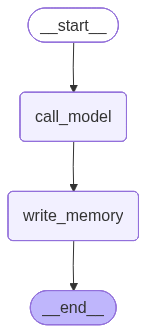

In [ ]:
from IPython.display import Image, display

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.store.base import BaseStore

from langchain_core.messages import HumanMessage, SystemMessage, AIMessage
from langchain_core.runnables.config import RunnableConfig

# Chatbot instruction
MODEL_SYSTEM_MESSAGE = """You are a helpful assistant with memory that provides information about the user. 
If you have memory for this user, use it to personalize your responses.
Here is the memory (it may be empty): {memory}"""

# Create new memory from the chat history and any existing memory
CREATE_MEMORY_INSTRUCTION = """Create or update a user profile memory based on the user's chat history. 
This will be saved for long-term memory. If there is an existing memory, simply update it. 
Here is the existing memory (it may be empty): {memory}"""


def call_model(state: MessagesState, config: RunnableConfig, store: BaseStore):
    """Load memory from the store and use it to personalize the chatbot's response."""

    # Get the user ID from the config
    user_id = config["configurable"]["user_id"]

    # Retrieve memory from the store
    namespace = ("memory", user_id)
    existing_memory = store.get(namespace, "user_memory")

    # Format the memories for the system prompt
    if existing_memory and existing_memory.value:
        memory_dict = existing_memory.value
        formatted_memory = (
            f"Name: {memory_dict.get('user_name', 'Unknown')}\n"
            f"Interests: {', '.join(memory_dict.get('interests', []))}"
        )
    else:
        formatted_memory = None

    # Format the memory in the system prompt
    system_msg = MODEL_SYSTEM_MESSAGE.format(memory=formatted_memory)

    # Respond using memory as well as the chat history
    response = model.invoke([SystemMessage(content=system_msg)] + state["messages"])

    return {"messages": response}


def write_memory(state: MessagesState, config: RunnableConfig, store: BaseStore):
    """Reflect on the chat history and save a memory to the store."""

    # Get the user ID from the config
    user_id = config["configurable"]["user_id"]

    # Retrieve existing memory from the store
    namespace = ("memory", user_id)
    existing_memory = store.get(namespace, "user_memory")

    # Format the memories for the system prompt
    if existing_memory and existing_memory.value:
        memory_dict = existing_memory.value
        formatted_memory = (
            f"Name: {memory_dict.get('user_name', 'Unknown')}\n"
            f"Interests: {', '.join(memory_dict.get('interests', []))}"
        )
    else:
        formatted_memory = None

    # Format the existing memory in the instruction
    system_msg = CREATE_MEMORY_INSTRUCTION.format(memory=formatted_memory)

    # Invoke the model to produce structured output that matches the schema
    new_memory = model_with_structure.invoke(
        [SystemMessage(content=system_msg)] + state["messages"]
    )

    # Overwrite the existing use profile memory
    key = "user_memory"
    store.put(namespace, key, new_memory)


# Define the graph
builder = StateGraph(MessagesState)
builder.add_node("call_model", call_model)
builder.add_node("write_memory", write_memory)
builder.add_edge(START, "call_model")
builder.add_edge("call_model", "write_memory")
builder.add_edge("write_memory", END)

# Store for long-term (across-thread) memory
across_thread_memory = InMemoryStore()

# Checkpointer for short-term (within-thread) memory
within_thread_memory = MemorySaver()

# Compile the graph with the checkpointer fir and store
graph = builder.compile(checkpointer=within_thread_memory, store=across_thread_memory)

# View
display(Image(graph.get_graph(xray=1).draw_mermaid_png()))

In [13]:
# We supply a thread ID for short-term (within-thread) memory
# We supply a user ID for long-term (across-thread) memory
config = {"configurable": {"thread_id": "1", "user_id": "1"}}

# User input
input_messages = [
    HumanMessage(
        content="Hi, my name is Lance and I like to bike around San Francisco and eat at bakeries."
    )
]

# Run the graph
for chunk in graph.stream({"messages": input_messages}, config, stream_mode="values"):
    chunk["messages"][-1].pretty_print()

================================ Human Message =================================

Hi, my name is Lance and I like to bike around San Francisco and eat at bakeries.
================================== Ai Message ==================================

Hi Lance! It's great to meet you. Biking around San Francisco sounds like a fantastic way to explore the city, and enjoying treats from bakeries is always a delight. Do you have any favorite bakeries in San Francisco that you like to visit?


查看 store 里的记忆,可以看到它是一个符合 schema 的字典。

In [14]:
# Namespace for the memory to save
user_id = "1"
namespace = ("memory", user_id)
existing_memory = across_thread_memory.get(namespace, "user_memory")
debug(existing_memory.value)

╭─────────────────────────────────────────────────── 🧠 Debug ────────────────────────────────────────────────────╮
│ {                                                                                                               │
│   "user_name": "Lance",                                                                                         │
│   "interests": [                                                                                                │
│     "biking",                                                                                                   │
│     "San Francisco",                                                                                            │
│     "bakeries"                                                                                                  │
│   ]                                                                                                             │
│ }                                                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## 什么时候会失败?

[`with_structured_output`](https://docs.langchain.com/oss/python/langchain/models#structured-outputs) 很好用,但遇到更复杂的 schema 会怎样?[这里](https://github.com/hinthornw/trustcall?tab=readme-ov-file#complex-schema)有个更复杂的例子,是描述用户沟通偏好和信任倾向的 [Pydantic](https://docs.pydantic.dev/latest/) 模型,下面来实测一下。

In [15]:
from typing import List, Optional


class OutputFormat(BaseModel):
    preference: str
    sentence_preference_revealed: str


class TelegramPreferences(BaseModel):
    preferred_encoding: Optional[List[OutputFormat]] = None
    favorite_telegram_operators: Optional[List[OutputFormat]] = None
    preferred_telegram_paper: Optional[List[OutputFormat]] = None


class MorseCode(BaseModel):
    preferred_key_type: Optional[List[OutputFormat]] = None
    favorite_morse_abbreviations: Optional[List[OutputFormat]] = None


class Semaphore(BaseModel):
    preferred_flag_color: Optional[List[OutputFormat]] = None
    semaphore_skill_level: Optional[List[OutputFormat]] = None


class TrustFallPreferences(BaseModel):
    preferred_fall_height: Optional[List[OutputFormat]] = None
    trust_level: Optional[List[OutputFormat]] = None
    preferred_catching_technique: Optional[List[OutputFormat]] = None


class CommunicationPreferences(BaseModel):
    telegram: TelegramPreferences
    morse_code: MorseCode
    semaphore: Semaphore


class UserPreferences(BaseModel):
    communication_preferences: CommunicationPreferences
    trust_fall_preferences: TrustFallPreferences


class TelegramAndTrustFallPreferences(BaseModel):
    pertinent_user_preferences: UserPreferences

用 `with_structured_output` 对这个复杂 schema 做提取试试。

In [16]:
from pydantic import ValidationError

# Bind schema to model
model_with_structure = model.with_structured_output(TelegramAndTrustFallPreferences)

# Conversation
conversation = """Operator: How may I assist with your telegram, sir?
Customer: I need to send a message about our trust fall exercise.
Operator: Certainly. Morse code or standard encoding?
Customer: Morse, please. I love using a straight key.
Operator: Excellent. What's your message?
Customer: Tell him I'm ready for a higher fall, and I prefer the diamond formation for catching.
Operator: Done. Shall I use our "Daredevil" paper for this daring message?
Customer: Perfect! Send it by your fastest carrier pigeon.
Operator: It'll be there within the hour, sir."""

# Invoke the model
try:
    model_with_structure.invoke(f"""Extract the preferences from the following conversation:
    <convo>
    {conversation}
    </convo>""")
except ValidationError as e:
    print(e)

<div class="dark-error" style="background:#2d1f1f; color:#fca5a5; padding:10px 24px; border-left:4px solid #f87171; border-radius:4px; width:97%;"><style>.dark-error strong{color:#fde047;}</style>

**反例/后果**:即便用高能力模型(如 `gpt-4o`)直接朴素提取复杂 schema,也容易出错——字段缺失、格式不对、嵌套结构解析错误都很常见。

</div>

## Trustcall:创建和更新 profile schema

复杂 schema 难提取,简单 schema 的**更新**也有坑。前面的 chatbot 每次要保存新记忆,都是**从零重新生成**整个 profile schema——低效(每次都要重新生成全部信息,浪费 token),而且容易在重新生成时丢失原有信息。

[TrustCall](https://github.com/hinthornw/trustcall) 就是为了解决这些问题而生的开源库,作者是 LangChain 团队的 [Will Fu-Hinthorn](https://github.com/hinthornw),专门针对记忆更新场景设计。

先看看 TrustCall 对一组 [messages](https://docs.langchain.com/oss/python/langchain/messages) 做简单提取的用法。

In [17]:
# Conversation
conversation = [
    HumanMessage(content="Hi, I'm Lance."),
    AIMessage(content="Nice to meet you, Lance."),
    HumanMessage(content="I really like biking around San Francisco."),
]

用 `create_extractor` 传入模型和 schema(作为 [tool](https://docs.langchain.com/oss/python/langchain/tools))。

TrustCall 支持多种方式提供 schema——JSON 对象、Python dict、Pydantic model 都行。底层用 [tool calling](https://docs.langchain.com/oss/python/langchain/models#tool-calling) 从输入的 [messages](https://docs.langchain.com/oss/python/langchain/messages) 里产出[结构化输出](https://docs.langchain.com/oss/python/langchain/models#structured-outputs)。

想强制 Trustcall 产出结构化输出,可以在 `tool_choice` 参数里指定 schema 名字。

In [ ]:
from trustcall import create_extractor


# Schema
class UserProfile(BaseModel):
    """User profile schema with typed fields"""

    user_name: str = Field(description="The user's preferred name")
    interests: List[str] = Field(description="A list of the user's interests")


# Initialize the model
model = ChatOpenAI(model="gpt-4o", temperature=0)

# Create the extractor
trustcall_extractor = create_extractor(
    model, tools=[UserProfile], tool_choice="UserProfile"
)

# Instruction
system_msg = "Extract the user profile from the following conversation"

# Invoke the extractor
result = trustcall_extractor.invoke(
    {"messages": [SystemMessage(content=system_msg)] + conversation}
)

调用 extractor 之后会拿到几样东西:

* `messages`:包含 tool call 的 `AIMessage` 列表
* `responses`:解析好、符合 schema 的 tool call 结果
* `response_metadata`:如果是在更新已有对象,这里会说明每个 response 对应哪个已有对象

In [22]:
for m in result["messages"]: 
    m.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  UserProfile (call_WZyRMcsJKBZ2FwinucLMhKLY)
 Call ID: call_WZyRMcsJKBZ2FwinucLMhKLY
  Args:
    user_name: Lance
    interests: ['biking around San Francisco']


In [23]:
schema = result["responses"]
schema

[UserProfile(user_name='Lance', interests=['biking around San Francisco'])]

In [24]:
schema[0].model_dump()

{'user_name': 'Lance', 'interests': ['biking around San Francisco']}

In [25]:
result["response_metadata"]

[{'id': 'call_WZyRMcsJKBZ2FwinucLMhKLY'}]

看看怎么用它来**更新** profile。

更新时,TrustCall 需要传入一组 messages 以及**已有的 schema**。核心思路是:让模型生成一个 [JSON Patch](https://jsonpatch.com/),只更新 schema 里真正变化的部分。

<div class="dark-info" style="background:#1e293b; color:#e2e8f0; padding:12px 24px; border-left:4px solid #60a5fa; border-radius:4px; width:97%;"><style>.dark-info strong{color:#fbbf24;}</style>

这比朴素地整体覆写 schema 更不容易出错,也更高效——模型只需要生成变化的那一小部分。

用 `model_dump()` 把 Pydantic model 实例序列化成 dict,传给 `"existing"` 参数,同时带上 schema 名字 `UserProfile`。

</div>

In [26]:
# Update the conversation
updated_conversation = [
    HumanMessage(content="Hi, I'm Lance."),
    AIMessage(content="Nice to meet you, Lance."),
    HumanMessage(content="I really like biking around San Francisco."),
    AIMessage(content="San Francisco is a great city! Where do you go after biking?"),
    HumanMessage(content="I really like to go to a bakery after biking."),
]

# Update the instruction
system_msg = """Update the memory (JSON doc) to incorporate new information from the following conversation"""

# Invoke the extractor with the updated instruction and existing profile with the corresponding tool name (UserProfile)
result = trustcall_extractor.invoke(
    {"messages": [SystemMessage(content=system_msg)] + updated_conversation},
    {"existing": {"UserProfile": schema[0].model_dump()}},
)

In [27]:
for m in result["messages"]: 
    m.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  UserProfile (call_mmvFvhOboReTuXB4xUwt2leM)
 Call ID: call_mmvFvhOboReTuXB4xUwt2leM
  Args:
    user_name: Lance
    interests: ['biking', 'visiting bakeries']


In [28]:
result["response_metadata"]

[{'id': 'call_mmvFvhOboReTuXB4xUwt2leM'}]

In [30]:
updated_schema = result["responses"][0]
debug(updated_schema.model_dump())

╭─────────────────────────────────────────────────── 🧠 Debug ────────────────────────────────────────────────────╮
│ {                                                                                                               │
│   "user_name": "Lance",                                                                                         │
│   "interests": [                                                                                                │
│     "biking",                                                                                                   │
│     "visiting bakeries"                                                                                         │
│   ]                                                                                                             │
│ }                                                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

LangSmith trace:

https://smith.langchain.com/public/229eae22-1edb-44c6-93e6-489124a43968/r

再拿前面那个更有挑战性的[复杂 schema](https://github.com/hinthornw/trustcall?tab=readme-ov-file#complex-schema)测一下 Trustcall。

In [31]:
bound = create_extractor(
    model,
    tools=[TelegramAndTrustFallPreferences],
    tool_choice="TelegramAndTrustFallPreferences",
)

# Conversation
conversation = """Operator: How may I assist with your telegram, sir?
Customer: I need to send a message about our trust fall exercise.
Operator: Certainly. Morse code or standard encoding?
Customer: Morse, please. I love using a straight key.
Operator: Excellent. What's your message?
Customer: Tell him I'm ready for a higher fall, and I prefer the diamond formation for catching.
Operator: Done. Shall I use our "Daredevil" paper for this daring message?
Customer: Perfect! Send it by your fastest carrier pigeon.
Operator: It'll be there within the hour, sir."""

result = bound.invoke(
    f"""Extract the preferences from the following conversation:
<convo>
{conversation}
</convo>"""
)

# Extract the preferences
result["responses"][0]

TelegramAndTrustFallPreferences(pertinent_user_preferences=UserPreferences(communication_preferences=CommunicationPreferences(telegram=TelegramPreferences(preferred_encoding=[OutputFormat(preference='standard encoding', sentence_preference_revealed='standard encoding')], favorite_telegram_operators=None, preferred_telegram_paper=None), morse_code=MorseCode(preferred_key_type=[OutputFormat(preference='straight key', sentence_preference_revealed='straight key')], favorite_morse_abbreviations=None), semaphore=Semaphore(preferred_flag_color=None, semaphore_skill_level=None)), trust_fall_preferences=TrustFallPreferences(preferred_fall_height=[OutputFormat(preference='higher', sentence_preference_revealed='higher')], trust_level=None, preferred_catching_technique=[OutputFormat(preference='diamond formation', sentence_preference_revealed='diamond formation')])))

Trace:

https://smith.langchain.com/public/5cd23009-3e05-4b00-99f0-c66ee3edd06e/r

更多例子可以看[这个概览视频](https://www.youtube.com/watch?v=-H4s0jQi-QY)。

<div class="dark-cyan" style="background:#0f2729; color:#a5f3fc; padding:10px 24px; border-left:4px solid #22d3ee; border-radius:4px; width:97%;"><style>.dark-cyan strong{color:#fbbf24;}</style>

**🆕 2026 更新**:Trustcall 目前仍在积极维护(最新版本 0.0.39 左右),`create_extractor` API 基本保持稳定。但它跟 LangGraph 的大版本升级(比如 0.3→1.x 的变动)耦合较紧,升级 LangGraph 后偶尔会遇到 `create_extractor` 导入失败或异步调用相关的问题,建议固定好 `langgraph`/`trustcall` 的版本组合,升级前查一下 [hinthornw/trustcall](https://github.com/hinthornw/trustcall) 的 issue 列表。

</div>

## 带 profile schema 更新的 Chatbot

把 Trustcall 接入 chatbot,让它能创建**并且更新**一份记忆 profile。

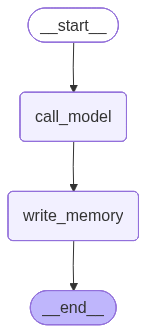

In [32]:
from IPython.display import Image, display

from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import StateGraph, MessagesState, START, END
from langchain_core.runnables.config import RunnableConfig
from langgraph.checkpoint.memory import MemorySaver
from langgraph.store.base import BaseStore

# Initialize the model
model = ChatOpenAI(model="gpt-4o", temperature=0)


# Schema
class UserProfile(BaseModel):
    """Profile of a user"""

    user_name: str = Field(description="The user's preferred name")
    user_location: str = Field(description="The user's location")
    interests: list = Field(description="A list of the user's interests")


# Create the extractor
trustcall_extractor = create_extractor(
    model,
    tools=[UserProfile],
    tool_choice="UserProfile",  # Enforces use of the UserProfile tool
)

# Chatbot instruction
MODEL_SYSTEM_MESSAGE = """You are a helpful assistant with memory that provides information about the user. 
If you have memory for this user, use it to personalize your responses.
Here is the memory (it may be empty): {memory}"""

# Extraction instruction
TRUSTCALL_INSTRUCTION = """Create or update the memory (JSON doc) to incorporate information from the following conversation:"""


def call_model(state: MessagesState, config: RunnableConfig, store: BaseStore):
    """Load memory from the store and use it to personalize the chatbot's response."""

    # Get the user ID from the config
    user_id = config["configurable"]["user_id"]

    # Retrieve memory from the store
    namespace = ("memory", user_id)
    existing_memory = store.get(namespace, "user_memory")

    # Format the memories for the system prompt
    if existing_memory and existing_memory.value:
        memory_dict = existing_memory.value
        formatted_memory = (
            f"Name: {memory_dict.get('user_name', 'Unknown')}\n"
            f"Location: {memory_dict.get('user_location', 'Unknown')}\n"
            f"Interests: {', '.join(memory_dict.get('interests', []))}"
        )
    else:
        formatted_memory = None

    # Format the memory in the system prompt
    system_msg = MODEL_SYSTEM_MESSAGE.format(memory=formatted_memory)

    # Respond using memory as well as the chat history
    response = model.invoke([SystemMessage(content=system_msg)] + state["messages"])

    return {"messages": response}


def write_memory(state: MessagesState, config: RunnableConfig, store: BaseStore):
    """Reflect on the chat history and save a memory to the store."""

    # Get the user ID from the config
    user_id = config["configurable"]["user_id"]

    # Retrieve existing memory from the store
    namespace = ("memory", user_id)
    existing_memory = store.get(namespace, "user_memory")

    # Get the profile as the value from the list, and convert it to a JSON doc
    existing_profile = (
        {"UserProfile": existing_memory.value} if existing_memory else None
    )

    # Invoke the extractor
    result = trustcall_extractor.invoke(
        {
            "messages": [SystemMessage(content=TRUSTCALL_INSTRUCTION)]
            + state["messages"],
            "existing": existing_profile,
        }
    )

    # Get the updated profile as a JSON object
    updated_profile = result["responses"][0].model_dump()

    # Save the updated profile
    key = "user_memory"
    store.put(namespace, key, updated_profile)


# Define the graph
builder = StateGraph(MessagesState)
builder.add_node("call_model", call_model)
builder.add_node("write_memory", write_memory)
builder.add_edge(START, "call_model")
builder.add_edge("call_model", "write_memory")
builder.add_edge("write_memory", END)

# Store for long-term (across-thread) memory
across_thread_memory = InMemoryStore()

# Checkpointer for short-term (within-thread) memory
within_thread_memory = MemorySaver()

# Compile the graph with the checkpointer fir and store
graph = builder.compile(checkpointer=within_thread_memory, store=across_thread_memory)

# View
display(Image(graph.get_graph(xray=1).draw_mermaid_png()))

In [33]:
# We supply a thread ID for short-term (within-thread) memory
# We supply a user ID for long-term (across-thread) memory
config = {"configurable": {"thread_id": "1", "user_id": "1"}}

# User input
input_messages = [HumanMessage(content="Hi, my name is Lance")]

# Run the graph
for chunk in graph.stream({"messages": input_messages}, config, stream_mode="values"):
    chunk["messages"][-1].pretty_print()

================================ Human Message =================================

Hi, my name is Lance
================================== Ai Message ==================================

Hello, Lance! It's nice to meet you. How can I assist you today?


In [34]:
# User input
input_messages = [HumanMessage(content="I like to bike around San Francisco")]

# Run the graph
for chunk in graph.stream({"messages": input_messages}, config, stream_mode="values"):
    chunk["messages"][-1].pretty_print()

================================ Human Message =================================

I like to bike around San Francisco
================================== Ai Message ==================================

That sounds like a fantastic way to explore the city! San Francisco has some great biking routes. Do you have a favorite trail or area you like to ride in?


In [35]:
# Namespace for the memory to save
user_id = "1"
namespace = ("memory", user_id)
existing_memory = across_thread_memory.get(namespace, "user_memory")
existing_memory.dict()

{'namespace': ['memory', '1'],
 'key': 'user_memory',
 'value': {'user_name': 'Lance',
  'user_location': 'San Francisco',
  'interests': ['biking']},
 'created_at': '2026-05-07T04:11:17.542766+00:00',
 'updated_at': '2026-05-07T04:11:17.542767+00:00'}

In [37]:
# The user profile saved as a JSON object
debug(existing_memory.value)

╭─────────────────────────────────────────────────── 🧠 Debug ────────────────────────────────────────────────────╮
│ {                                                                                                               │
│   "user_name": "Lance",                                                                                         │
│   "user_location": "San Francisco",                                                                             │
│   "interests": [                                                                                                │
│     "biking"                                                                                                    │
│   ]                                                                                                             │
│ }                                                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [38]:
# User input
input_messages = [HumanMessage(content="I also enjoy going to bakeries")]

# Run the graph
for chunk in graph.stream({"messages": input_messages}, config, stream_mode="values"):
    chunk["messages"][-1].pretty_print()

================================ Human Message =================================

I also enjoy going to bakeries
================================== Ai Message ==================================

San Francisco has some amazing bakeries to explore. Do you have a favorite bakery, or are you looking for recommendations to try on your next ride?


在一个新 thread 里继续对话。

In [39]:
# We supply a thread ID for short-term (within-thread) memory
# We supply a user ID for long-term (across-thread) memory
config = {"configurable": {"thread_id": "2", "user_id": "1"}}

# User input
input_messages = [HumanMessage(content="What bakeries do you recommend for me?")]

# Run the graph
for chunk in graph.stream({"messages": input_messages}, config, stream_mode="values"):
    chunk["messages"][-1].pretty_print()

================================ Human Message =================================

What bakeries do you recommend for me?
================================== Ai Message ==================================

Since you're in San Francisco and enjoy going to bakeries, here are a few recommendations you might like:

1. **Tartine Bakery** - Known for its delicious bread and pastries, it's a must-visit for any bakery enthusiast.
2. **B. Patisserie** - Offers a delightful selection of French pastries, including their famous kouign-amann.
3. **Arsicault Bakery** - Renowned for its croissants, which have been praised as some of the best in the city.
4. **Craftsman and Wolves** - Known for their inventive pastries and the "Rebel Within," a savory muffin with a soft-cooked egg inside.
5. **Mr. Holmes Bakehouse** - Famous for their cruffins and other creative baked goods.

These spots should offer a great variety of treats for you to enjoy on your bakery adventures around the city!


Trace:

https://smith.langchain.com/public/f45bdaf0-6963-4c19-8ec9-f4b7fe0f68ad/r

## Studio

![Screenshot 2024-10-30 at 11.26.31 AM.png](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/6732d0437060f1754ea79908_Screenshot%202024-11-11%20at%207.48.53%E2%80%AFPM.png)

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**:朴素的 `with_structured_output` 整体覆写容易丢信息、难处理复杂 schema;Trustcall 用 JSON Patch 做增量更新,既省 token 又不容易破坏已有数据。

</div>